# Weather Summary Classification

Predicting the daily weather summary (like "Partly Cloudy" or "Foggy") from weather measurements such as temperature, humidity, wind speed, and pressure.

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_style('whitegrid')

## 2. Loading the data

In [2]:
df = pd.read_csv("weatherHistory.csv")
print(df.shape)
df.head()

(96453, 11)


,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251,15.8263,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259,15.8263,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204,14.9569,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269,15.8263,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259,15.8263,1016.51,Partly cloudy throughout the day.


In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  object 
 1   Summary                   96453 non-null  object 
 2   Precip Type               95936 non-null  object 
 3   Temperature (C)           96453 non-null  float64
 4   Apparent Temperature (C)  96453 non-null  float64
 5   Humidity                  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  int64  
 8   Visibility (km)           96453 non-null  float64
 9   Pressure (millibars)      96453 non-null  float64
 10  Daily Summary             96453 non-null  object 
dtypes: float64(6), int64(1), object(4)
memory usage: 8.1+ MB


,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars)
count,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000
mean,11.932678,10.855029,0.734899,10.810640,187.509232,10.347325,1003.235956
std,9.551546,10.696847,0.195473,6.913571,107.383428,4.192123,116.969906
min,-21.822222,-27.716667,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.688889,2.311111,0.600000,5.828200,116.000000,8.339800,1011.900000
50%,12.000000,12.000000,0.780000,9.965900,180.000000,10.046400,1016.450000
75%,18.838889,18.838889,0.890000,14.135800,290.000000,14.812000,1021.090000
max,39.905556,39.344444,1.000000,63.852600,359.000000,16.100000,1046.380000


In [4]:
print("Missing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
Formatted Date                0
Summary                       0
Precip Type                 517
Temperature (C)               0
Apparent Temperature (C)      0
Humidity                      0
Wind Speed (km/h)             0
Wind Bearing (degrees)        0
Visibility (km)               0
Pressure (millibars)          0
Daily Summary                 0
dtype: int64

Duplicate rows: 24


## 3. Data preprocessing

#### duplicates

In [5]:
# Dropping duplicate rows before splitting so the same row can't end up in both train and test
rows_before = len(df)
df = df.drop_duplicates()
print(f"Dropped {rows_before - len(df)} duplicate rows, {len(df)} rows left")

Dropped 24 duplicate rows, 96429 rows left


#### date features

In [6]:
# Daily Summary is one label per day, so keeping the plain calendar date to split by day later
df['Date'] = df['Formatted Date'].str[:10]

# The date has a timezone, so converting with utc=True
df['Formatted Date'] = pd.to_datetime(df['Formatted Date'], utc=True, errors='coerce')

# Sorting by time so the "change over last hours" feature below is correct
df = df.sort_values('Formatted Date').reset_index(drop=True)

df['Year'] = df['Formatted Date'].dt.year
df['Month'] = df['Formatted Date'].dt.month
df['Day'] = df['Formatted Date'].dt.day
df['Hour'] = df['Formatted Date'].dt.hour
df['DayOfWeek'] = df['Formatted Date'].dt.dayofweek   # Monday=0
df['DayOfYear'] = df['Formatted Date'].dt.dayofyear
df['WeekOfYear'] = df['Formatted Date'].dt.isocalendar().week.astype(int)

# Season: 1=Winter, 2=Spring, 3=Summer, 4=Fall
season_map = {12: 1, 1: 1, 2: 1, 3: 2, 4: 2, 5: 2, 6: 3, 7: 3, 8: 3, 9: 4, 10: 4, 11: 4}
df['Season'] = df['Month'].map(season_map)

# Original date column is no longer needed
df = df.drop('Formatted Date', axis=1)
print(f"Date range: {df['Date'].min()} to {df['Date'].max()} ({df['Date'].nunique()} days)")
print("Added: Date, Year, Month, Day, Hour, DayOfWeek, DayOfYear, WeekOfYear, Season")
print("Shape:", df.shape)

Date range: 2006-01-01 to 2016-12-31 (4018 days)
Added: Date, Year, Month, Day, Hour, DayOfWeek, DayOfYear, WeekOfYear, Season
Shape: (96429, 19)


#### zero-pressure fix

In [7]:
# Pressure of 0 mb and humidity of exactly 0 are not real readings (missing values stored as 0)
zero_pressure = df['Pressure (millibars)'] == 0
zero_humidity = df['Humidity'] == 0
print("Rows with pressure = 0:", zero_pressure.sum())
print("Rows with humidity = 0:", zero_humidity.sum())
print("Rows with both:", (zero_pressure & zero_humidity).sum())

# Setting them to missing, they get filled with the train median after the split
df.loc[zero_pressure, 'Pressure (millibars)'] = np.nan
df.loc[zero_humidity, 'Humidity'] = np.nan

Rows with pressure = 0: 1288
Rows with humidity = 0: 22
Rows with both: 0


#### feature engineering

In [8]:
# Interaction features
df['Temp_Feel_Diff'] = df['Temperature (C)'] - df['Apparent Temperature (C)']  # wind chill / heat effect
df['Humidity_x_Temp'] = df['Humidity'] * df['Temperature (C)']

# Temporal feature
# Falling pressure usually comes before rain, so using the change over the last 3 hours
df['Pressure_Change_3h'] = df['Pressure (millibars)'].diff(3)
print("Added: Temp_Feel_Diff, Humidity_x_Temp, Pressure_Change_3h")
print("Missing in Pressure_Change_3h:", df['Pressure_Change_3h'].isna().sum(), "(filled later with the train median)")
print(df[['Temp_Feel_Diff', 'Humidity_x_Temp', 'Pressure_Change_3h']].describe().round(2))

Added: Temp_Feel_Diff, Humidity_x_Temp, Pressure_Change_3h
Missing in Pressure_Change_3h: 1746 (filled later with the train median)
       Temp_Feel_Diff  Humidity_x_Temp  Pressure_Change_3h
count        96429.00         96407.00            94683.00
mean             1.08             7.59                0.00
std              1.68             5.74                1.36
min             -4.81           -17.46              -17.31
25%              0.00             3.64               -0.67
50%              0.00             8.11                0.01
75%              2.22            11.92                0.67
max             10.18            22.94               18.47


#### remove Summary (data leakage)

In [9]:
# Summary describes the weather directly, so it would leak the answer to the model
df = df.drop('Summary', axis=1)
print("Dropped Summary, columns left:", df.shape[1])

Dropped Summary, columns left: 21


#### group Daily Summary into categories

In [10]:
# 214 unique summaries are too many, so grouping them into broader categories by keyword.
# Order matters: rain and fog are checked before the cloud words so they take priority.
s = df['Daily Summary'].str.lower()

conditions = [
    s.str.contains('clear throughout'),
    s.str.contains('rain|drizzle'),
    s.str.startswith('foggy') | s.str.contains('foggy throughout'),
    s.str.startswith('overcast'),
    s.str.startswith('mostly cloudy'),
    s.str.startswith('partly cloudy'),
    s.str.startswith('breezy') | s.str.startswith('windy'),   # both are wind-related, merged
]
categories = ['Clear', 'Rainy', 'Foggy', 'Overcast', 'Mostly Cloudy', 'Partly Cloudy', 'Breezy']

# anything that doesn't match goes to Others
df['Weather_Category'] = np.select(conditions, categories, default='Others')
print(f"{df['Daily Summary'].nunique()} unique summaries grouped into {df['Weather_Category'].nunique()} categories")
counts = df['Weather_Category'].value_counts()
print(pd.DataFrame({'rows': counts, 'percent': (counts / len(df) * 100).round(2)}))

214 unique summaries grouped into 7 categories
                   rows  percent
Weather_Category                
Partly Cloudy     40579    42.08
Mostly Cloudy     31436    32.60
Foggy             18821    19.52
Overcast           3600     3.73
Clear               913     0.95
Breezy              840     0.87
Rainy               240     0.25


#### grouping validation

In [11]:
# Checking the keyword grouping against the weather measurements themselves.
# Idea: if a summary label was grouped correctly, its average weather should be
# closest to the average weather of its own category.
num_cols = ['Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Visibility (km)', 'Pressure (millibars)']
z = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()

label_centre = z.groupby(df['Daily Summary']).mean()
category_centre = z.groupby(df['Weather_Category']).mean()

# distance from every label to every category centre
dist = pd.DataFrame({c: ((label_centre - category_centre.loc[c]) ** 2).sum(axis=1) ** 0.5
                     for c in category_centre.index})

check = pd.DataFrame({
    'assigned': df.groupby('Daily Summary')['Weather_Category'].first(),
    'closest': dist.idxmin(axis=1),
    'rows': df['Daily Summary'].value_counts()
})

# only looking at labels with enough rows to be reliable
big = check[check['rows'] >= 100]
mismatch = big[big['assigned'] != big['closest']]
print(f"{len(mismatch)} of {len(big)} labels sit closer to a different category")
print(f"{mismatch['rows'].sum() / big['rows'].sum():.1%} of rows affected")
mismatch.sort_values('rows', ascending=False).head(10)

19 of 67 labels sit closer to a different category
4.5% of rows affected


,assigned,closest,rows
Daily Summary,,,
Partly cloudy starting overnight continuing until evening.,Partly Cloudy,Clear,719
Mostly cloudy throughout the day and breezy in the morning.,Mostly Cloudy,Breezy,360
Partly cloudy starting in the morning continuing until afternoon.,Partly Cloudy,Clear,312
Mostly cloudy throughout the day and breezy starting in the morning continuing until afternoon.,Mostly Cloudy,Breezy,288
Partly cloudy in the afternoon.,Partly Cloudy,Clear,264
Foggy in the evening.,Foggy,Overcast,240
Partly cloudy throughout the day and breezy starting in the morning continuing until afternoon.,Partly Cloudy,Breezy,216
Mostly cloudy throughout the day and breezy in the afternoon.,Mostly Cloudy,Breezy,216
Mostly cloudy starting overnight continuing until evening.,Mostly Cloudy,Overcast,216


#### encode the target

In [12]:
# Daily Summary is replaced by the grouped category, so dropping it
df = df.drop('Daily Summary', axis=1)

# Label encoding the target. It's a fixed mapping of the class names to numbers,
# so it's safe to do before the split.
label_encoder = LabelEncoder()
df['Target_Encoded'] = label_encoder.fit_transform(df['Weather_Category'])
print(f"Encoded {len(label_encoder.classes_)} classes:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))

Encoded 7 classes: {'Breezy': 0, 'Clear': 1, 'Foggy': 2, 'Mostly Cloudy': 3, 'Overcast': 4, 'Partly Cloudy': 5, 'Rainy': 6}


## 4. Train / validation / test split

Each day has one summary label shared by all its hourly rows, so I split by date. Splitting by row would put hours of the same day in both train and test.

In [13]:
# Every row of a day has the same label and nearly the same weather.
# A random row split would put rows of the same day in both train and test (leakage),
# so splitting by DATE instead: a whole day goes to train, validation or test.
dates = df['Date'].unique()
train_dates, temp_dates = train_test_split(dates, test_size=0.30, random_state=42)
val_dates, test_dates = train_test_split(temp_dates, test_size=0.50, random_state=42)

train_df = df[df['Date'].isin(train_dates)].copy()
val_df = df[df['Date'].isin(val_dates)].copy()
test_df = df[df['Date'].isin(test_dates)].copy()

print(f"Total: {len(dates)} days, {len(df)} rows")
for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f"{name}: {d['Date'].nunique()} days, {len(d)} rows")

# no day should appear in more than one set
shared = len(set(train_dates) & set(val_dates)) + len(set(train_dates) & set(test_dates)) + len(set(val_dates) & set(test_dates))
print("Days shared between sets:", shared)

# rows per category in each set
print(pd.DataFrame({'train': train_df['Weather_Category'].value_counts(),
                    'val': val_df['Weather_Category'].value_counts(),
                    'test': test_df['Weather_Category'].value_counts()}).fillna(0).astype(int))

Total: 4018 days, 96429 rows
train: 2812 days, 67485 rows
val: 603 days, 14473 rows
test: 603 days, 14471 rows
Days shared between sets: 0
                  train   val  test
Weather_Category                   
Breezy              600    48   192
Clear               720    73   120
Foggy             13346  2425  3050
Mostly Cloudy     22005  5255  4176
Overcast           2592   528   480
Partly Cloudy     28054  6120  6405
Rainy               168    24    48


Rare classes have very few days: Rainy has 7 days in train, 1 in validation and 2 in test. Per-class scores for Rainy, Breezy and Clear are therefore based on very few days and may change a lot with a different split, so I read them with caution.

## 5. Exploratory data analysis (train set only)

In [14]:
# Same color for the same category in every plot, in a logical order
category_order = ['Clear', 'Partly Cloudy', 'Mostly Cloudy', 'Overcast', 'Foggy', 'Rainy', 'Breezy']
colors = {'Clear': '#F4B400', 'Partly Cloudy': '#8ECAE6', 'Mostly Cloudy': '#6C8EBF',
          'Overcast': '#555555', 'Foggy': '#B39DDB', 'Rainy': '#1D3557', 'Breezy': '#2A9D8F'}

px.defaults.template = 'plotly_white'
px.defaults.color_discrete_map = colors
px.defaults.category_orders = {'Weather_Category': category_order}

#### target distribution

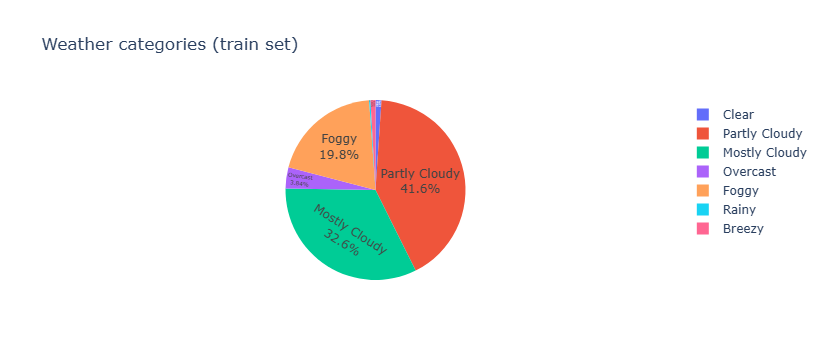

In [15]:
# From here on only the training set is used, so test data can't influence any decision
px.pie(train_df, names='Weather_Category', title='Weather categories (train set)').update_traces(
    textposition='inside', textinfo='percent+label').show()

**What this shows**
- The classes are imbalanced. Partly Cloudy (41.6%), Mostly Cloudy (32.6%) and Foggy (19.8%) make up about 94% of the training data.
- Overcast is about 3.8%. Clear, Breezy and Rainy are each around 1% or less. Rainy has only 240 rows in the full data, which is about 10 days.
- Accuracy alone would look good even if the rare classes are never predicted, so I will also check precision and recall for each class and try class weights.

#### distribution of numerical features

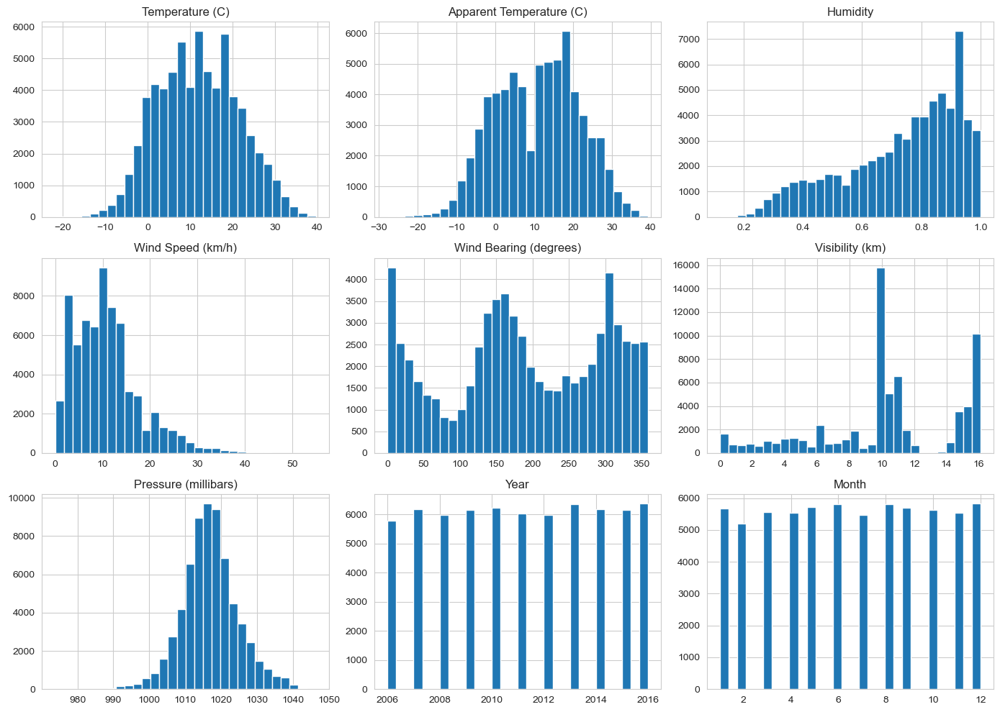

In [16]:
weather_cols = ['Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)',
                'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)']

train_df[weather_cols + ['Year', 'Month']].hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()

**What this shows**
- Temperature and Apparent Temperature are roughly bell-shaped, centred around 10-15°C.
- Humidity is skewed towards high values, most days are between 0.6 and 1.0.
- Wind Speed is right-skewed, most readings are below 20 km/h with a few strong-wind days.
- Wind Bearing covers the full 0-360 range with no single dominant direction.
- Visibility has two big spikes, at about 10 km and 16 km, which looks like rounded or capped sensor values.
- Pressure had a few readings of 0, which are impossible. I treated these (and humidity of 0) as missing and filled them with the train median.
- Year and Month are evenly spread, about the same number of rows for every year from 2006 to 2016 and for every month.

#### correlation heatmap

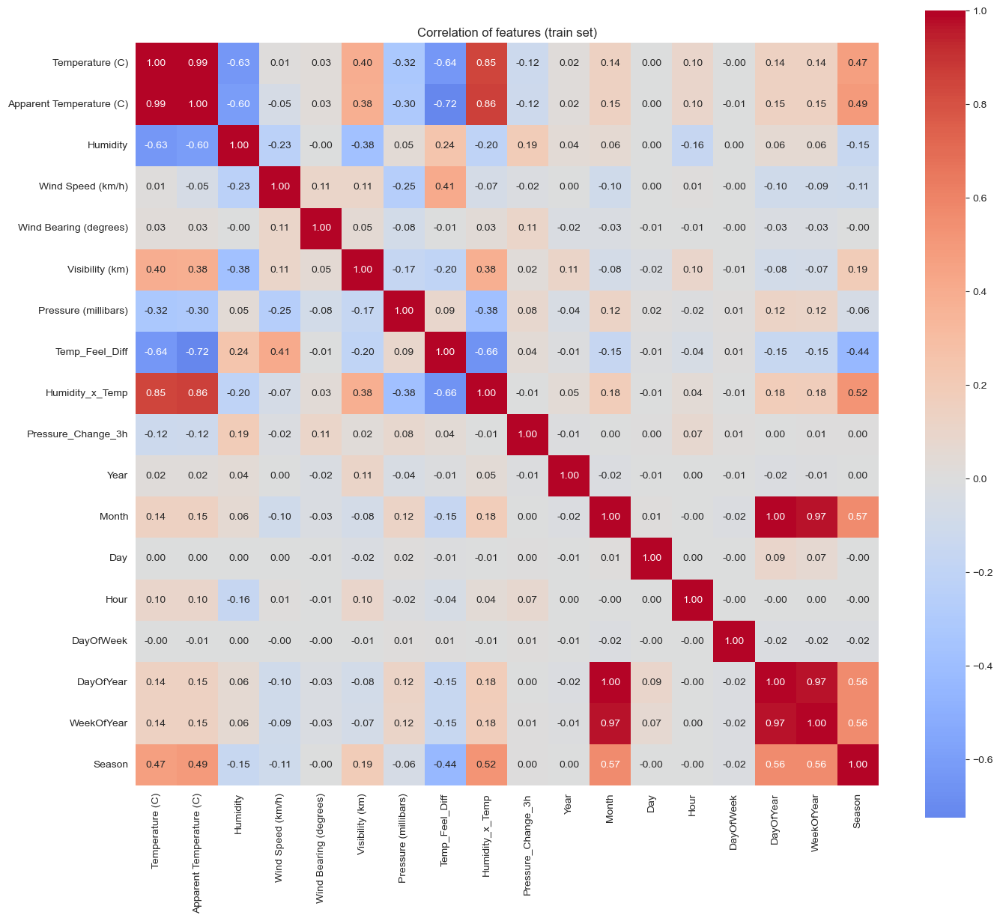

Apparent Temperature (C)  Temp_Feel_Diff             -0.724454
Temperature (C)           Humidity_x_Temp             0.846835
Apparent Temperature (C)  Humidity_x_Temp             0.860294
Month                     WeekOfYear                  0.970460
DayOfYear                 WeekOfYear                  0.971929
Temperature (C)           Apparent Temperature (C)    0.992595
Month                     DayOfYear                   0.996468
dtype: float64


In [17]:
corr_cols = weather_cols + ['Temp_Feel_Diff', 'Humidity_x_Temp', 'Pressure_Change_3h',
                            'Year', 'Month', 'Day', 'Hour', 'DayOfWeek', 'DayOfYear', 'WeekOfYear', 'Season']
corr = train_df[corr_cols].corr()

plt.figure(figsize=(16, 14))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation of features (train set)')
plt.show()

# Pairs with |correlation| > 0.7, using the upper triangle so each pair shows once
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pairs[pairs.abs() > 0.7].sort_values())

**What this shows**
- Temperature and Apparent Temperature are almost the same feature (0.99).
- Month, DayOfYear and WeekOfYear are near duplicates (0.97 to 0.99) because they all measure the time of year. Tree-based models handle this fine.
- Humidity_x_Temp is correlated with both temperatures (about 0.85) because it is built from them.
- Temp_Feel_Diff has a negative correlation with Apparent Temperature (-0.72), so it adds wind and humidity information on top of the temperature.
- Humidity and Temperature are negatively correlated (-0.63): warmer hours tend to be drier.
- None of the weather features is strongly correlated with the hour or day of the week.

#### features by weather category

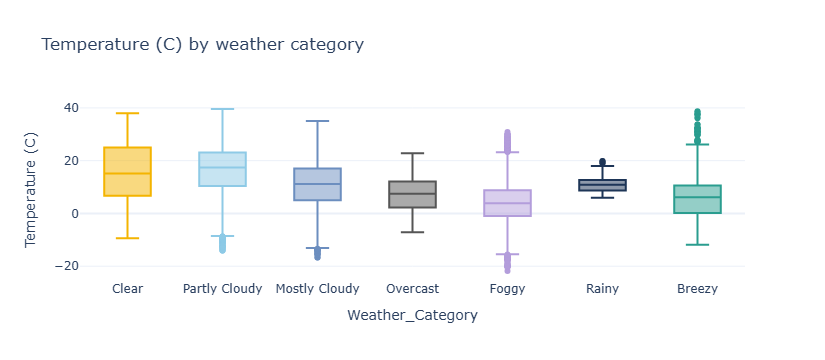

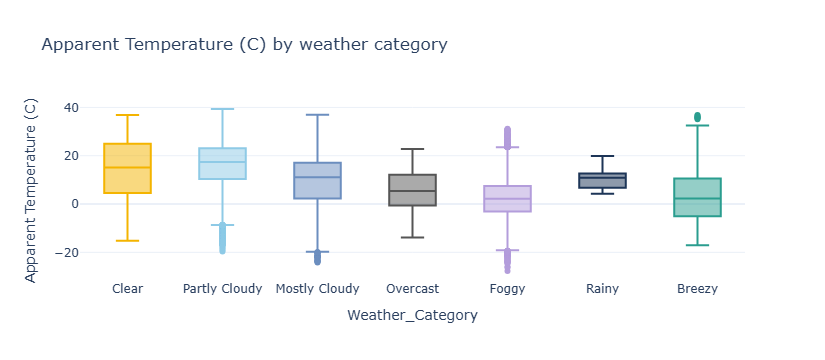

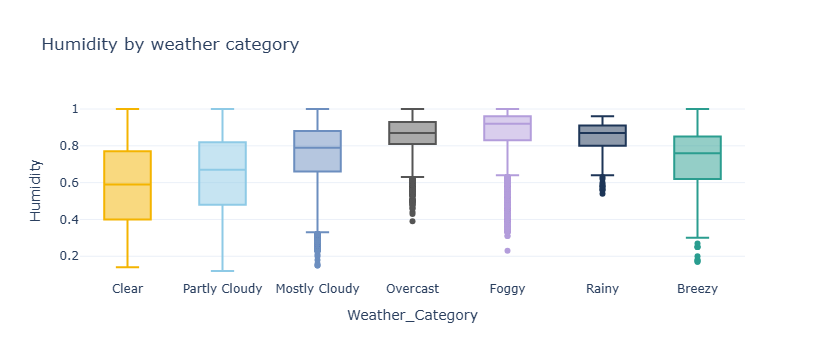

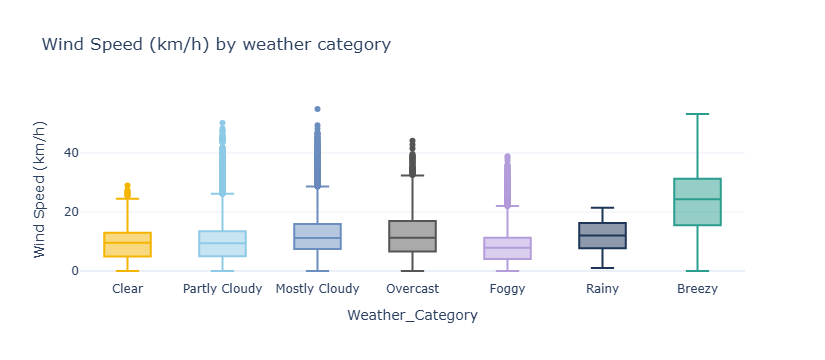

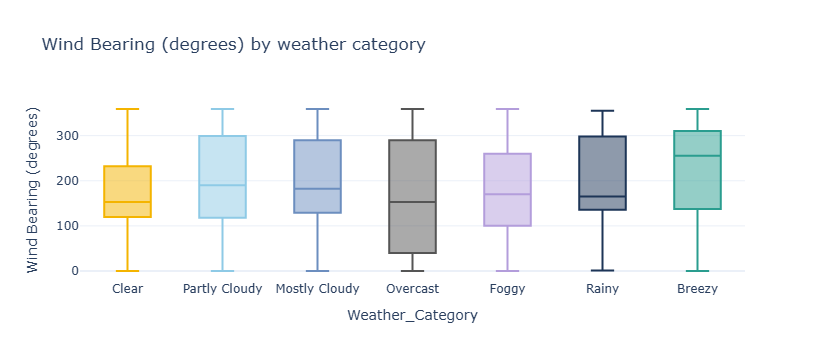

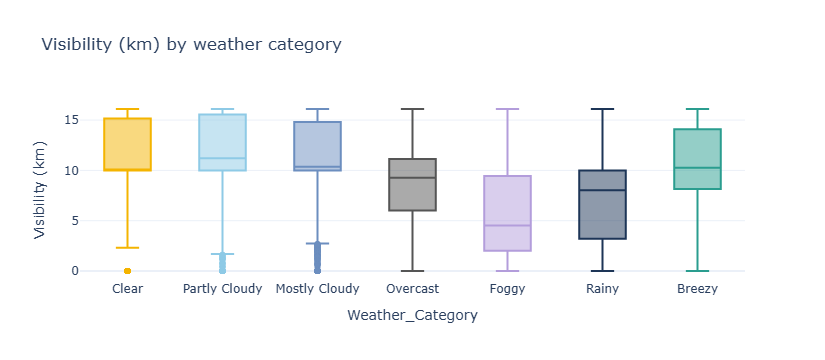

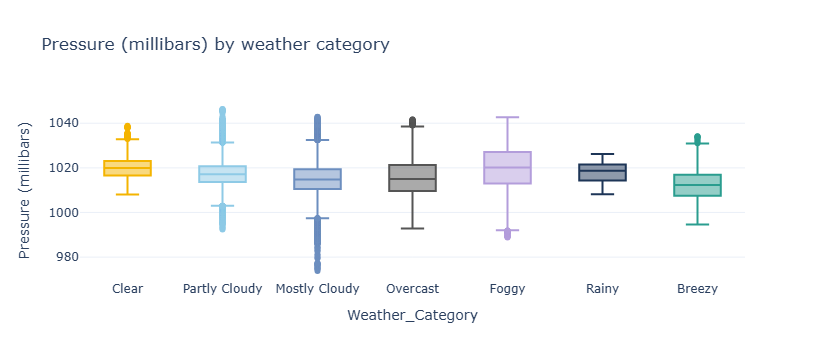

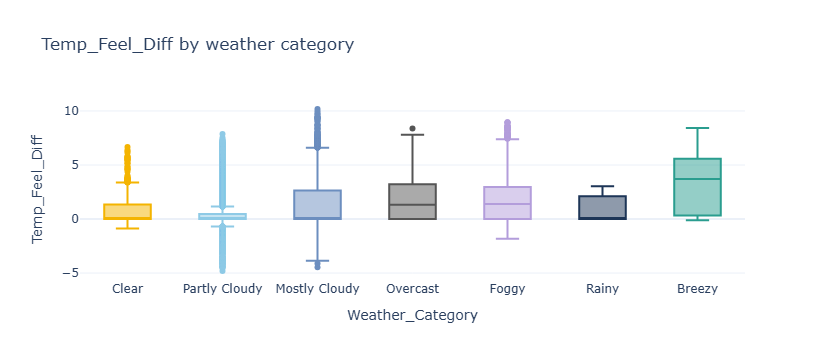

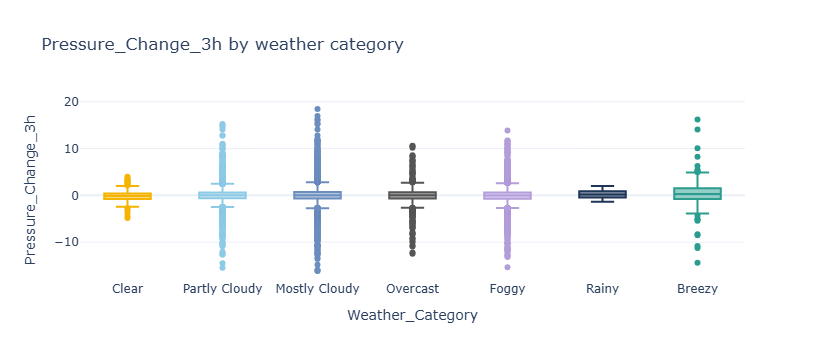

In [18]:
# The last two are the new features, checking if they separate the categories
key_features = weather_cols + ['Temp_Feel_Diff', 'Pressure_Change_3h']

for feature in key_features:
    px.box(train_df, x='Weather_Category', y=feature, color='Weather_Category',
           title=f'{feature} by weather category').update_layout(showlegend=False).show()

**What this shows**
- **Temperature:** Partly Cloudy and Clear are the warmest (median about 15-17°C), Foggy is the coldest (about 4°C). Rainy sits in a narrow band around 10-12°C. Apparent Temperature looks almost the same.
- **Humidity:** Foggy, Overcast and Rainy have high humidity (median about 0.87-0.92), Clear is the lowest (about 0.59).
- **Wind Speed:** Breezy is clearly the highest (median about 24 km/h against 8-12 for the others). This is expected, because Breezy and Windy are defined by wind, so it is the easiest class to separate.
- **Visibility:** Foggy is the lowest (median about 4.5 km), Rainy and Overcast are in the middle, the rest are around 10-11 km.
- **Wind Bearing:** the boxes overlap for all categories, so it gives little help on its own.
- **Temp_Feel_Diff:** Breezy has the biggest gap (median about 3.7°C, a wind chill effect), and Partly Cloudy is close to 0 with a very tight box.
- **Pressure:** after removing the invalid zero readings, all categories sit around 1010-1025 mb with a lot of overlap. Breezy is the lowest (median about 1012) and Foggy and Clear are the highest (about 1020), which fits with windy weather coming with lower pressure and calm or foggy weather with higher pressure.
- **Pressure_Change_3h:** every category is centred at 0 with a similar spread. Breezy has a slightly wider box and Clear and Rainy slightly narrower, so it is a weak signal. I will check its feature importance in the model and drop it if it is near the bottom.
- Partly Cloudy and Mostly Cloudy overlap on most features, so I expect the model to confuse these two the most.

#### weather category by month and season

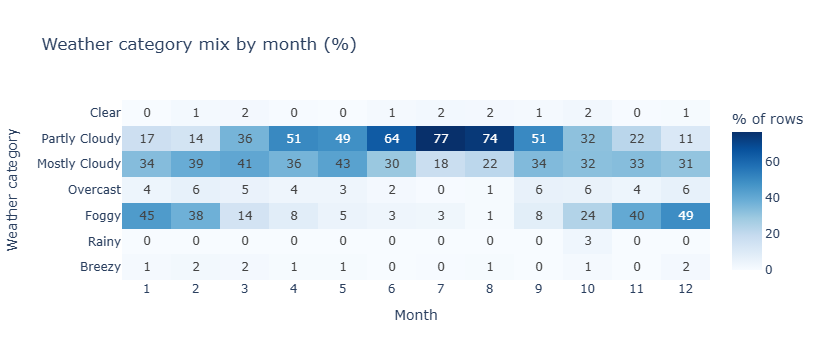

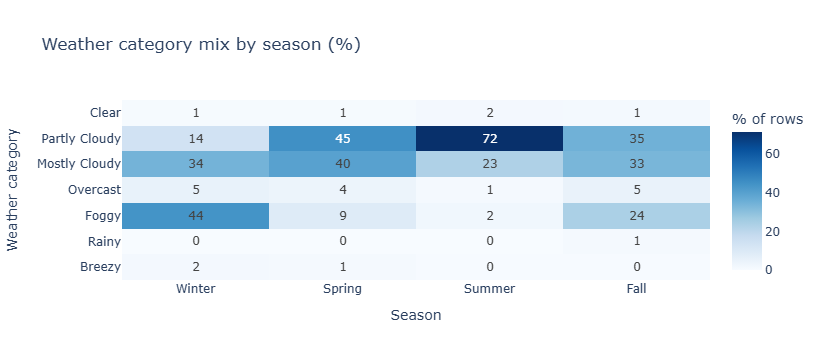

In [19]:
# % of each month's rows that belong to each category (every column adds up to 100)
month_mix = (pd.crosstab(train_df['Weather_Category'], train_df['Month'], normalize='columns')
             .mul(100).reindex(category_order))
px.imshow(month_mix, text_auto='.0f', aspect='auto', color_continuous_scale='Blues',
          labels=dict(x='Month', y='Weather category', color='% of rows'),
          title='Weather category mix by month (%)').update_xaxes(dtick=1).show()

# Same for season
season_names = {1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Fall'}
season_mix = (pd.crosstab(train_df['Weather_Category'], train_df['Season'].map(season_names), normalize='columns')
              .mul(100).reindex(category_order)[['Winter', 'Spring', 'Summer', 'Fall']])
px.imshow(season_mix, text_auto='.0f', aspect='auto', color_continuous_scale='Blues',
          labels=dict(x='Season', y='Weather category', color='% of rows'),
          title='Weather category mix by season (%)').show()

**What this shows**
- **Winter:** Foggy is the biggest group (about 44%), followed by Mostly Cloudy (about 35%). Partly Cloudy is only about 14%.
- **Summer:** Partly Cloudy dominates (about 70%) and Foggy almost disappears (about 2%).
- **Spring and Fall** sit in between. Spring is mostly Partly Cloudy and Mostly Cloudy (about 45% and 40%), while Fall is split roughly evenly between Partly Cloudy, Mostly Cloudy and Foggy.
- Month by month, Foggy is highest from November to February and nearly absent from June to August. Overcast is about 5% in the cooler months and close to 0 in summer.
- In the training data, Rainy appears only in October (about 7 days). With so few days, the model could just learn "October means Rainy" from Month or DayOfYear, so Rainy results should be read with caution.
- Month and season clearly carry information about the weather category, so I keep them as features.

#### scatter plots

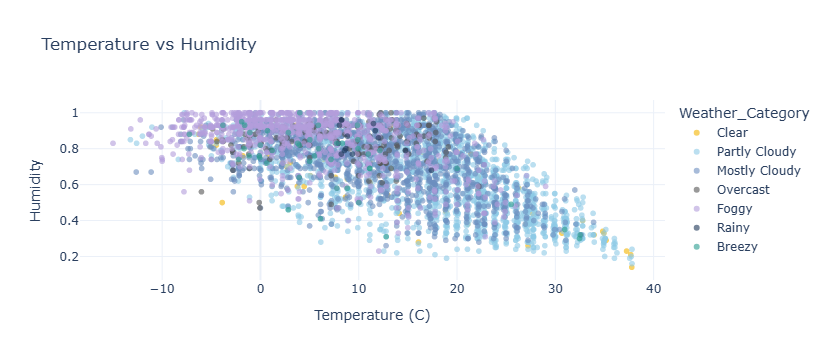

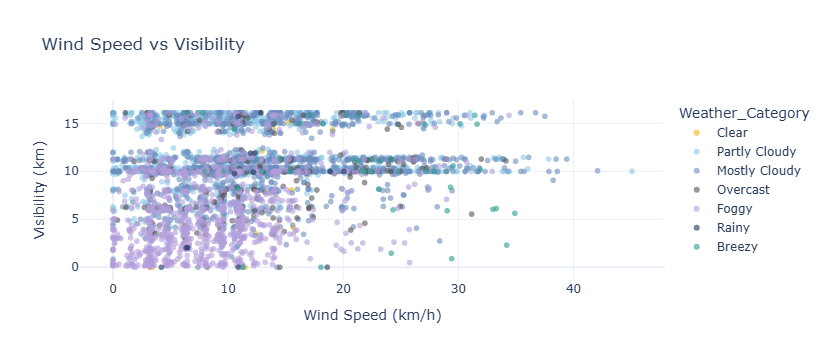

In [20]:
# Plotting a sample of 5000 rows, since all rows would be too crowded to read
sample = train_df.sample(5000, random_state=42)

px.scatter(sample, x='Temperature (C)', y='Humidity', color='Weather_Category',
           opacity=0.6, title='Temperature vs Humidity').show()
px.scatter(sample, x='Wind Speed (km/h)', y='Visibility (km)', color='Weather_Category',
           opacity=0.6, title='Wind Speed vs Visibility').show()

**What this shows**
- **Temperature vs Humidity:** humidity falls as temperature rises, and there are almost no very humid points above 30°C. Foggy points sit in the cool, humid top-left area, while Partly Cloudy points dominate the warm, drier lower-right area. Mostly Cloudy is spread across the middle.
- **Wind Speed vs Visibility:** points form horizontal bands at about 10 km and 16 km, which are rounded or capped visibility values. Low visibility (under 5 km) is mostly Foggy. Strong wind (above 20 km/h) has fewer points, and Breezy shows up mainly there.
- In both plots the categories overlap a lot, so no pair of features separates them on its own. The model needs to combine several features.

## 6. missing values, filled using train values

In [21]:
# Precip Type: filling missing values with the most frequent value of the TRAIN set
mode_value = train_df['Precip Type'].mode()[0]

# Numerical columns (including the new features): filling with the TRAIN median,
# which is not affected by outliers
num_cols = ['Temperature (C)', 'Apparent Temperature (C)', 'Humidity',
            'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)',
            'Pressure (millibars)', 'Temp_Feel_Diff', 'Humidity_x_Temp', 'Pressure_Change_3h']
train_medians = train_df[num_cols].median()

# counting missing values before filling
sets = {'train': train_df, 'val': val_df, 'test': test_df}
print("Missing before filling:")
for name, d in sets.items():
    print(f"  {name}: Precip Type = {d['Precip Type'].isna().sum()}, numerical = {d[num_cols].isna().sum().sum()}")

for d in sets.values():
    d['Precip Type'] = d['Precip Type'].fillna(mode_value)
    d[num_cols] = d[num_cols].fillna(train_medians)

print(f"\nPrecip Type filled with train mode: '{mode_value}'")
print("Numerical columns filled with train medians:")
print(train_medians.round(2).to_string())
print("\nMissing after filling:", sum(d[['Precip Type'] + num_cols].isna().sum().sum() for d in sets.values()))

Missing before filling:
  train: Precip Type = 345, numerical = 2097
  val: Precip Type = 118, numerical = 433
  test: Precip Type = 54, numerical = 548

Precip Type filled with train mode: 'rain'
Numerical columns filled with train medians:
Temperature (C)               12.02
Apparent Temperature (C)      12.02
Humidity                       0.78
Wind Speed (km/h)              9.89
Wind Bearing (degrees)       180.00
Visibility (km)               10.05
Pressure (millibars)        1016.69
Temp_Feel_Diff                 0.00
Humidity_x_Temp                8.13
Pressure_Change_3h             0.02

Missing after filling: 0


## 7. features and target

In [22]:
# Weather_Category is only for readable plots, Date is only used for splitting and grouping.
# The model uses Target_Encoded as the target.
drop_cols = ['Weather_Category', 'Target_Encoded', 'Date']

X_train, y_train = train_df.drop(columns=drop_cols), train_df['Target_Encoded']
X_val, y_val = val_df.drop(columns=drop_cols), val_df['Target_Encoded']
X_test, y_test = test_df.drop(columns=drop_cols), test_df['Target_Encoded']

print(f"X_train {X_train.shape}, X_val {X_val.shape}, X_test {X_test.shape}")
print(f"Number of features: {X_train.shape[1]}")
print("Features:", list(X_train.columns))
print("Non-numeric columns left:", list(X_train.select_dtypes(exclude='number').columns))
print("Missing values left in X_train:", X_train.isna().sum().sum())

# class counts with readable names instead of the encoded numbers
class_names = dict(enumerate(label_encoder.classes_))
print("\nTarget classes in train:")
print(y_train.map(class_names).value_counts().to_string())

X_train (67485, 19), X_val (14473, 19), X_test (14471, 19)
Number of features: 19
Features: ['Precip Type', 'Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)', 'Year', 'Month', 'Day', 'Hour', 'DayOfWeek', 'DayOfYear', 'WeekOfYear', 'Season', 'Temp_Feel_Diff', 'Humidity_x_Temp', 'Pressure_Change_3h']
Non-numeric columns left: ['Precip Type']
Missing values left in X_train: 0

Target classes in train:
Target_Encoded
Partly Cloudy    28054
Mostly Cloudy    22005
Foggy            13346
Overcast          2592
Clear              720
Breezy             600
Rainy              168


## 8. Outlier capping

#### bounds from the train set

In [23]:
# The 7 original weather columns (the new features are not capped)
weather_cols = ['Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)',
                'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)']

# Outlier bounds with the IQR rule, calculated from TRAIN only
bounds = {}
rows = []
for col in weather_cols:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    bounds[col] = (low, high)

    n_out = ((X_train[col] < low) | (X_train[col] > high)).sum()
    rows.append({'feature': col, 'lower': round(low, 2), 'upper': round(high, 2),
                 'train outliers': n_out, 'percent': round(n_out / len(X_train) * 100, 2)})

print(pd.DataFrame(rows).to_string(index=False))

                 feature   lower   upper  train outliers  percent
         Temperature (C)  -16.96   40.29              25     0.04
Apparent Temperature (C)  -22.59   43.67              20     0.03
                Humidity    0.15    1.35               5     0.01
       Wind Speed (km/h)   -6.52   26.45            2213     3.28
  Wind Bearing (degrees) -147.50  552.50               0     0.00
         Visibility (km)   -1.83   24.90               0     0.00
    Pressure (millibars)  999.17 1034.42            2473     3.66


#### cap train, validation and test with the same bounds

In [24]:
# Values outside the bounds are clipped to the bound (not removed), using the TRAIN bounds for all sets
sets = {'train': X_train, 'val': X_val, 'test': X_test}
capped = {}
for name, X_set in sets.items():
    capped[name] = {}
    for col, (low, high) in bounds.items():
        capped[name][col] = ((X_set[col] < low) | (X_set[col] > high)).sum()
        X_set[col] = X_set[col].clip(low, high)

print("Values capped per feature:")
print(pd.DataFrame(capped))

Values capped per feature:
                          train  val  test
Temperature (C)              25    0    11
Apparent Temperature (C)     20    0     2
Humidity                      5    0     1
Wind Speed (km/h)          2213  383   497
Wind Bearing (degrees)        0    0     0
Visibility (km)               0    0     0
Pressure (millibars)       2473  527   597


Bounds use the IQR rule and are calculated on the train set only, then applied to validation and test. Wind Speed (3.3%) and Pressure (3.7%) have the most outliers, and the other columns have almost none. Values are clipped to the bound, not removed, so no rows are lost.

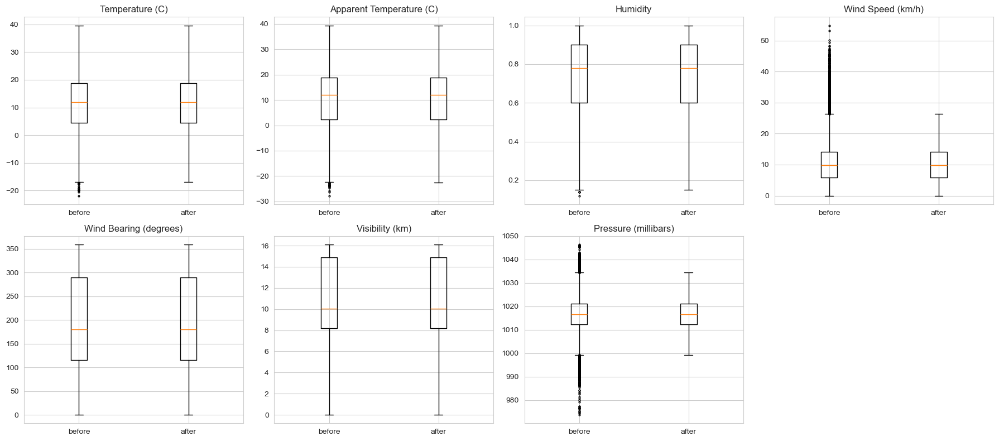

                          min before  min after  max before  max after
Temperature (C)               -21.82     -16.96       39.59      39.59
Apparent Temperature (C)      -27.72     -22.59       39.34      39.34
Humidity                        0.12       0.15        1.00       1.00
Wind Speed (km/h)               0.00       0.00       54.88      26.45
Wind Bearing (degrees)          0.00       0.00      359.00     359.00
Visibility (km)                 0.00       0.00       16.10      16.10
Pressure (millibars)          973.78     999.18     1046.38    1034.42


In [25]:
# train_df still has the values before capping, X_train has them after capping
before = train_df.loc[X_train.index, weather_cols]
after = X_train[weather_cols]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), weather_cols):
    ax.boxplot([before[col], after[col]], flierprops={'markersize': 2})
    ax.set_xticklabels(['before', 'after'])
    ax.set_title(col)
axes.ravel()[-1].axis('off')   # 7 features, so the 8th box is empty
plt.tight_layout()
plt.show()

# the same thing in numbers
print(pd.DataFrame({'min before': before.min(), 'min after': after.min(),
                    'max before': before.max(), 'max after': after.max()}).round(2))

**What this shows**
- Capping changes the shape of Wind Speed (3.3% of values) and Pressure (3.7%) the most. The long tail of extreme values is cut at the IQR bounds.
- Temperature, Apparent Temperature and Humidity barely change, and Wind Bearing and Visibility are untouched.
- The center and spread of every feature stay the same, so the cleaning removes only extreme values and does not distort the data.

## 9. Class imbalance

In [26]:
from sklearn.utils.class_weight import compute_sample_weight

counts = y_train.value_counts()
print(f"Rarest class: {counts.min()} rows, most common: {counts.max()} rows, ratio {counts.min() / counts.max():.3f}")

# Strong imbalance, so instead of changing the data, giving rare classes a higher weight during training.
# 'balanced' weight = total rows / (number of classes * rows of that class)
sample_weights = compute_sample_weight('balanced', y_train)
weights = pd.Series(sample_weights, index=y_train.index).groupby(y_train.map(class_names)).first().round(2)
print("\nWeight per class:")
print(weights.to_string())

Rarest class: 168 rows, most common: 28054 rows, ratio 0.006

Weight per class:
Target_Encoded
Breezy           16.07
Clear            13.39
Foggy             0.72
Mostly Cloudy     0.44
Overcast          3.72
Partly Cloudy     0.34
Rainy            57.39


The rarest class (Rainy) has 168 training rows against 28,054 for Partly Cloudy, a ratio of 0.006. Instead of oversampling, I use balanced class weights so rare classes count more during training and the data itself is unchanged. Rainy, Breezy and Clear rest on very few days, so their scores should be read with care.

## 10. One-hot encoding

In [27]:
# drop='first' avoids the dummy variable trap. The encoder learns categories from TRAIN only.
ohe = OneHotEncoder(sparse_output=False, drop='first')
ohe.fit(X_train[['Precip Type']])

# used on all three sets, so a function is worth it here
def encode_precip(d):
    encoded = pd.DataFrame(ohe.transform(d[['Precip Type']]),
                           columns=ohe.get_feature_names_out(['Precip Type']), index=d.index)
    return pd.concat([d.drop('Precip Type', axis=1), encoded], axis=1)

print("Precip Type counts in train before encoding:")
print(X_train['Precip Type'].value_counts().to_string())

X_train, X_val, X_test = encode_precip(X_train), encode_precip(X_val), encode_precip(X_test)

dropped = ohe.categories_[0][ohe.drop_idx_[0]]
print(f"\nCategories found in train: {list(ohe.categories_[0])}")
print(f"Category dropped (reference): '{dropped}'")
print(f"New column(s) created: {list(ohe.get_feature_names_out(['Precip Type']))}")
print(f"Shapes after encoding: train {X_train.shape}, val {X_val.shape}, test {X_test.shape}")
print("Non-numeric columns left:", list(X_train.select_dtypes(exclude='number').columns))
print("Missing values left in X_train:", X_train.isna().sum().sum())

Precip Type counts in train before encoding:
Precip Type
rain    59689
snow     7796

Categories found in train: ['rain', 'snow']
Category dropped (reference): 'rain'
New column(s) created: ['Precip Type_snow']
Shapes after encoding: train (67485, 19), val (14473, 19), test (14471, 19)
Non-numeric columns left: []
Missing values left in X_train: 0


## 11. Scaling

In [28]:
# The scaler learns mean and std from the capped TRAIN set only, then is applied to all three sets
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=X_train.columns, index=X_val.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_train.columns, index=X_test.index)

print(f"Scaled {X_train.shape[1]} features: train {X_train_scaled.shape}, val {X_val_scaled.shape}, test {X_test_scaled.shape}")
check = pd.DataFrame({'mean': [d.mean().abs().max() for d in (X_train_scaled, X_val_scaled, X_test_scaled)],
                      'std': [d.std().mean() for d in (X_train_scaled, X_val_scaled, X_test_scaled)]},
                     index=['train', 'val', 'test']).round(3)
print("\nLargest |mean| and average std after scaling:")
print(check)

Scaled 19 features: train (67485, 19), val (14473, 19), test (14471, 19)

Largest |mean| and average std after scaling:
        mean    std
train  0.000  1.000
val    0.093  0.982
test   0.041  1.000


## 12. Cross-validation folds

In [29]:
from sklearn.model_selection import StratifiedGroupKFold

# Rows of the same day stay in the same fold (group), and each fold gets
# a similar share of every weather category (stratify)
groups = train_df.loc[X_train.index, 'Date']
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
folds = list(cv.split(X_train_scaled, y_train, groups))

# checks: no day in both train and validation part of a fold, and every class present in every fold
shared_days = sum(len(set(groups.iloc[tr]) & set(groups.iloc[va])) for tr, va in folds)
print("Days shared between train and validation parts of any fold:", shared_days)

fold_table = pd.DataFrame({f'fold {i + 1}': y_train.iloc[va].map(class_names).value_counts()
                           for i, (tr, va) in enumerate(folds)}).fillna(0).astype(int)
print("\nRows per class in each validation fold:")
print(fold_table)

Days shared between train and validation parts of any fold: 0

Rows per class in each validation fold:
                fold 1  fold 2  fold 3  fold 4  fold 5
Target_Encoded                                        
Breezy              72     144     120      96     168
Clear              168      96     192     120     144
Foggy             2641    2785    2663    2832    2425
Mostly Cloudy     4560    3959    4512    4247    4727
Overcast           576     624     456     624     312
Partly Cloudy     5472    5856    5498    5543    5685
Rainy               24      24      48      24      48


5-fold StratifiedGroupKFold on the train set: all rows of one day stay in the same fold (no day is shared between the training and validation part of any fold), and the folds have similar category shares. Rainy has only 7 days in train, so each fold holds just 1 or 2 Rainy days. I checked that every fold contains every class.

## 13. Feature importance

Year                        0.1417
DayOfYear                   0.1121
Day                         0.0772
WeekOfYear                  0.0743
Pressure (millibars)        0.0726
Visibility (km)             0.0667
Wind Speed (km/h)           0.0639
Humidity                    0.0471
Temperature (C)             0.0452
DayOfWeek                   0.0446
Humidity_x_Temp             0.0445
Apparent Temperature (C)    0.0428
Month                       0.0397
Wind Bearing (degrees)      0.0348
Temp_Feel_Diff              0.0305
Pressure_Change_3h          0.0233
Season                      0.0226
Hour                        0.0146
Precip Type_snow            0.0017


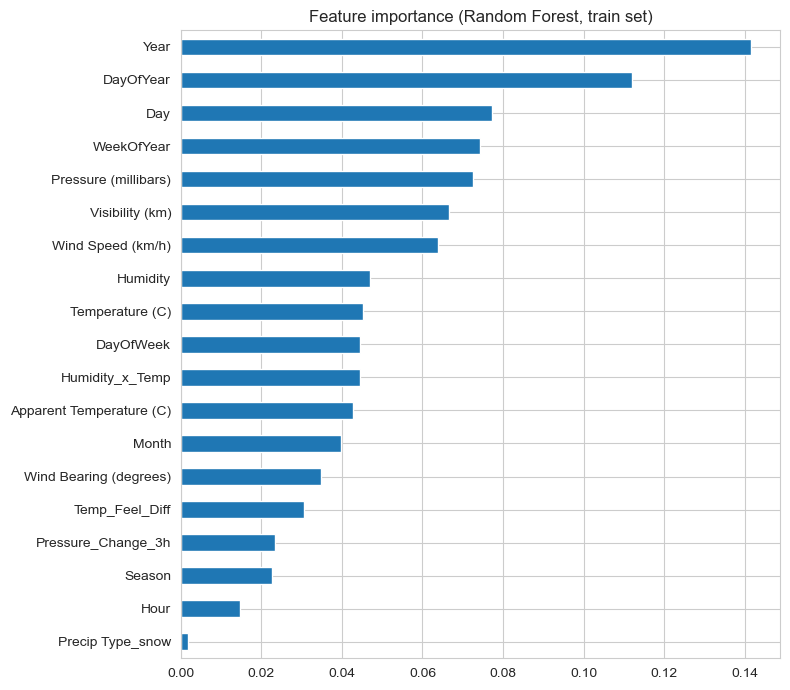

In [30]:
# Random Forest on the train set, with the class weights from the imbalance step
rf_importance = RandomForestClassifier(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1)
rf_importance.fit(X_train_scaled, y_train, sample_weight=sample_weights)

importance = pd.Series(rf_importance.feature_importances_, index=X_train.columns).sort_values()
print(importance.sort_values(ascending=False).round(4).to_string())

importance.plot.barh(figsize=(8, 7), title='Feature importance (Random Forest, train set)')
plt.tight_layout()
plt.show()

Visibility and Pressure are among the most useful weather features, which makes sense (fog means low visibility). Year, DayOfYear, Day and WeekOfYear also rank high, but these are only dates, not weather. Weather lasts several days, so a model can use the date to recognise days that are next to days it has already seen. I test this below.

# 14. Feature-set test

#### Do the date features really help?

In [31]:
from sklearn.metrics import f1_score

date_ids = ['Year', 'Day', 'DayOfYear', 'WeekOfYear', 'DayOfWeek', 'Hour']
engineered = ['Temp_Feel_Diff', 'Humidity_x_Temp', 'Pressure_Change_3h', 'Season']
feature_sets = {
    'A: all 19 features': list(X_train.columns),
    'B: without date-identifier features': [c for c in X_train.columns if c not in date_ids],
    'C: B without engineered features': [c for c in X_train.columns if c not in date_ids + engineered],
}

# used many times below, so a function is worth it
def macro_f1(cols, tr, va):
    rf = RandomForestClassifier(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1)
    rf.fit(X_train_scaled.iloc[tr][cols], y_train.iloc[tr], sample_weight=sample_weights[tr])
    pred = rf.predict(X_train_scaled.iloc[va][cols])
    return f1_score(y_train.iloc[va], pred, average='macro', zero_division=0)

# time-based check: train on early years, test on later years (both taken from the train set)
early = np.where(X_train['Year'] <= 2013)[0]
late = np.where(X_train['Year'] > 2013)[0]

rows = []
for name, cols in feature_sets.items():
    cv_scores = [macro_f1(cols, tr, va) for tr, va in folds]
    rows.append({'feature set': name, 'n features': len(cols),
                 'CV macro F1 (random days)': round(np.mean(cv_scores), 3),
                 'std': round(np.std(cv_scores), 3),
                 'macro F1 (train 2006-13, test 2014-16)': round(macro_f1(cols, early, late), 3)})
print(pd.DataFrame(rows).to_string(index=False))

                        feature set  n features  CV macro F1 (random days)   std  macro F1 (train 2006-13, test 2014-16)
                 A: all 19 features          19                      0.401 0.036                                   0.249
B: without date-identifier features          13                      0.320 0.024                                   0.263
   C: B without engineered features           9                      0.318 0.028                                   0.263


I compared three feature sets with the same model in two ways: 5-fold cross-validation on random days, and training on 2006-2013 and testing on 2014-2016.

| Feature set | Random days | Later years |
|---|---|---|
| A: all 19 features | 0.401 | 0.249 |
| B: without date features | 0.320 | 0.263 |
| C: B without engineered features | 0.318 | 0.263 |

- The date features raise the score on random days, but not on later years. They help the model recognise neighbouring days, not learn weather, so I removed them.
- The interaction and temporal features (Temp_Feel_Diff, Humidity_x_Temp, Pressure_Change_3h, Season) gave no improvement (0.318 vs 0.320), so I removed them to keep the model simple.

## 15. Final feature set

In [32]:
# Final features: the 7 weather measurements, Month and Precip Type_snow
final_features = feature_sets['C: B without engineered features']
print(f"{len(final_features)} features:", final_features)

# Same scaled data as before, only these columns (each column is scaled on its own, so nothing changes)
X_train_final = X_train_scaled[final_features]
X_val_final = X_val_scaled[final_features]
X_test_final = X_test_scaled[final_features]
print("Shapes:", X_train_final.shape, X_val_final.shape, X_test_final.shape)

9 features: ['Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)', 'Month', 'Precip Type_snow']
Shapes: (67485, 9) (14473, 9) (14471, 9)


Final features (9): Temperature, Apparent Temperature, Humidity, Wind Speed, Wind Bearing, Visibility, Pressure, Month and Precip Type_snow. A model without date features also needs only weather readings and the month as input when it is deployed.

## 16. Model Training & comparison

#### Models

In [33]:
from sklearn.base import clone
from sklearn.ensemble import AdaBoostClassifier, HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import f1_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.svm import LinearSVC

# Same models and settings as before, plus three more gradient boosting models
models = {
    'Logistic Regression': LogisticRegression(max_iter=500, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=20, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=50, max_depth=20, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=50, max_depth=5, random_state=42),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(max_depth=5, early_stopping=False, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=50, max_depth=5, random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(n_estimators=50, max_depth=5, random_state=42, n_jobs=-1, verbose=-1),
    'AdaBoost': AdaBoostClassifier(n_estimators=50, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=7, n_jobs=-1),
    'Naive Bayes': GaussianNB(),
    'SVM (linear)': LinearSVC(C=1.0, dual=False, max_iter=5000, random_state=42),
}
print(f"{len(models)} models:", list(models))

11 models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'Hist Gradient Boosting', 'XGBoost', 'LightGBM', 'AdaBoost', 'K-Nearest Neighbors', 'Naive Bayes', 'SVM (linear)']


11 models are compared: Logistic Regression, SVM (linear), Naive Bayes, KNN, Decision Tree, Random Forest, AdaBoost and four gradient boosting models (Gradient Boosting, Hist Gradient Boosting, XGBoost, LightGBM). All use the final 9 features, and every model except KNN gets the class weights.

#### Train & Compare

In [34]:
# Models are compared on the TRAIN set only (cross-validation), validation is a final check, test is not touched
labels = list(range(len(label_encoder.classes_)))
rows, trained, per_class = [], {}, {}

for name, model in models.items():
    # KNN has no sample weight option, every other model gets the class weights
    use_w = name != 'K-Nearest Neighbors'

    # 5-fold cross-validation on the train set (days stay together, every class in every fold)
    cv_f1 = []
    for tr, va in folds:
        m = clone(model)
        kw = {'sample_weight': sample_weights[tr]} if use_w else {}
        m.fit(X_train_final.iloc[tr], y_train.iloc[tr], **kw)
        cv_f1.append(f1_score(y_train.iloc[va], m.predict(X_train_final.iloc[va]), average='macro', zero_division=0))

    # then fit on the full train set and score on train and validation
    kw = {'sample_weight': sample_weights} if use_w else {}
    model.fit(X_train_final, y_train, **kw)
    trained[name] = model
    pred_train, pred_val = model.predict(X_train_final), model.predict(X_val_final)

    train_f1 = f1_score(y_train, pred_train, average='macro', zero_division=0)
    val_f1 = f1_score(y_val, pred_val, average='macro', zero_division=0)
    per_class[name] = f1_score(y_val, pred_val, average=None, labels=labels, zero_division=0)
    rows.append({'Model': name, 'CV macro F1': np.mean(cv_f1), 'CV std': np.std(cv_f1),
                 'Train macro F1': train_f1, 'Val macro F1': val_f1, 'Gap (train - val)': train_f1 - val_f1,
                 'Val accuracy': accuracy_score(y_val, pred_val)})
    print(f"{name}: CV macro F1 {np.mean(cv_f1):.3f}, validation macro F1 {val_f1:.3f}")

results = pd.DataFrame(rows).set_index('Model').sort_values('CV macro F1', ascending=False).round(3)
print("\nModel comparison (sorted by CV macro F1):")
print(results)

print("\nF1 per class on the validation set:")
print(pd.DataFrame(per_class, index=label_encoder.classes_).round(2))

Logistic Regression: CV macro F1 0.229, validation macro F1 0.211
Decision Tree: CV macro F1 0.274, validation macro F1 0.253
Random Forest: CV macro F1 0.304, validation macro F1 0.289
Gradient Boosting: CV macro F1 0.314, validation macro F1 0.294
Hist Gradient Boosting: CV macro F1 0.317, validation macro F1 0.288
XGBoost: CV macro F1 0.315, validation macro F1 0.281
LightGBM: CV macro F1 0.308, validation macro F1 0.282
AdaBoost: CV macro F1 0.237, validation macro F1 0.197
K-Nearest Neighbors: CV macro F1 0.293, validation macro F1 0.280
Naive Bayes: CV macro F1 0.262, validation macro F1 0.245
SVM (linear): CV macro F1 0.197, validation macro F1 0.175

Model comparison (sorted by CV macro F1):
                        CV macro F1  CV std  Train macro F1  Val macro F1  \
Model                                                                       
Hist Gradient Boosting        0.317   0.021           0.515         0.288   
XGBoost                       0.315   0.016           0.464 

**What this shows**
- Models are ranked by 5-fold cross-validated macro F1 on the train set. The five best (Hist Gradient Boosting 0.317, XGBoost 0.315, Gradient Boosting 0.314, LightGBM 0.308, Random Forest 0.304) are within 0.013 of each other, which is smaller than the fold-to-fold variation (std about 0.02). They are effectively tied.
- Random Forest (train 0.987 vs validation 0.289), Decision Tree (0.852 vs 0.253) and KNN (0.721 vs 0.280) memorise the training data. The boosting models overfit less, and LightGBM least (gap 0.12 against 0.15 to 0.23 for the other three).
- Logistic Regression (0.229), SVM (0.197) and AdaBoost (0.237) score lowest, so a simple linear rule is not enough for this problem.
- Random Forest has the highest validation accuracy (0.607), but its macro F1 is not better than the boosting models. It gets there by predicting the large classes well. I rank by macro F1 because it also counts the rare classes.
- Per class, the pattern is the same for every model: Foggy and Partly Cloudy are predicted best (F1 about 0.6 to 0.7), Mostly Cloudy is middling (0.3 to 0.5), Overcast is low (about 0.1 to 0.2), and Breezy and Clear are almost never right (F1 below 0.1). Rainy is 0.00 for every model.
- Hist Gradient Boosting has the best cross-validated score and trains fast, so I use it for tuning. Because the top models are tied, this is a practical choice rather than a clear win.

#### Best Model in Detail

Best model: Hist Gradient Boosting
               precision    recall  f1-score   support

       Breezy       0.03      0.31      0.05        48
        Clear       0.02      0.25      0.04        73
        Foggy       0.64      0.61      0.62      2425
Mostly Cloudy       0.53      0.42      0.47      5255
     Overcast       0.13      0.41      0.20       528
Partly Cloudy       0.71      0.58      0.64      6120
        Rainy       0.00      0.00      0.00        24

     accuracy                           0.51     14473
    macro avg       0.29      0.37      0.29     14473
 weighted avg       0.61      0.51      0.55     14473



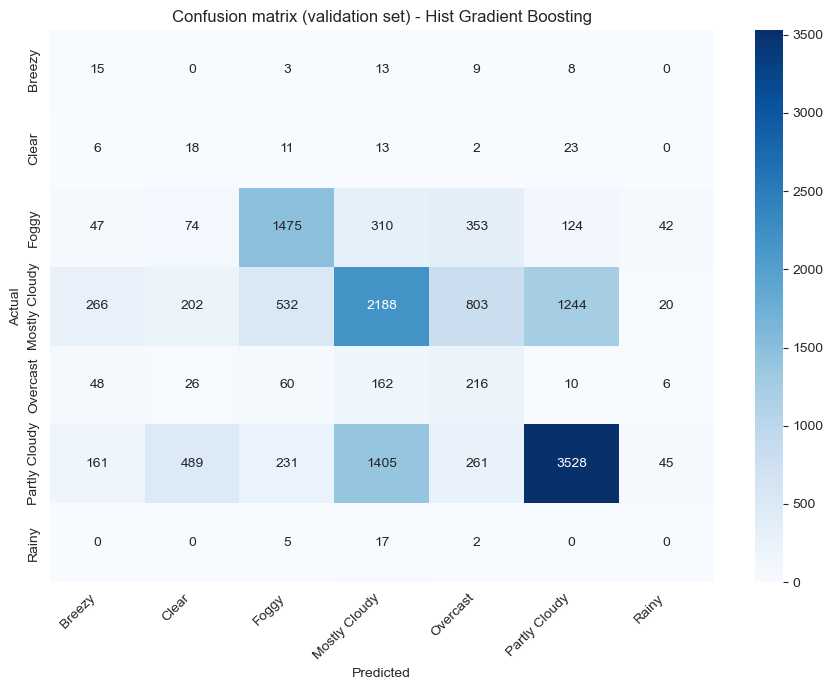

In [35]:
# Best model by cross-validation on the train set
best_name = results.index[0]
best_pred = trained[best_name].predict(X_val_final)
print("Best model:", best_name)
print(classification_report(y_val, best_pred, labels=labels, target_names=label_encoder.classes_, zero_division=0))

cm = confusion_matrix(y_val, best_pred, labels=labels)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title(f'Confusion matrix (validation set) - {best_name}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [36]:
from sklearn.dummy import DummyClassifier

# Baseline: always predict the most common class (Partly Cloudy)
base_pred = DummyClassifier(strategy='most_frequent').fit(X_train_final, y_train).predict(X_val_final)
print("Baseline accuracy:", round(accuracy_score(y_val, base_pred), 3))
print("Baseline macro F1:", round(f1_score(y_val, base_pred, average='macro', zero_division=0), 3))

Baseline accuracy: 0.423
Baseline macro F1: 0.085


**What this shows (validation set)**
- Hist Gradient Boosting reaches 0.51 accuracy and 0.29 macro F1. A baseline that always predicts the most common class (Partly Cloudy) gets 0.42 accuracy and 0.085 macro F1, so the model is clearly better than guessing, but the score is modest.
- Foggy (F1 0.62) and Partly Cloudy (0.64) are predicted best. Mostly Cloudy (0.47) is often confused with Partly Cloudy (1,244 and 1,405 rows in the confusion matrix), and Overcast (0.20) with Foggy and Mostly Cloudy.
- Breezy and Clear have recall of 0.31 and 0.25 but precision of only 0.03 and 0.02: the class weights make the model guess them too often. Rainy (24 validation rows, a single day) is never predicted correctly.
- The label describes the whole day's sky, but each row has one hour of readings and no cloud-cover feature, which limits every model on the cloudy categories.

## 17. Hyperparameter tuning

#### random search

In [37]:
from sklearn.model_selection import RandomizedSearchCV

# class_weight='balanced' gives the same weights as before, but built into the model,
# so the search scores plain macro F1 (no weights in the scoring)
base_hgb = HistGradientBoostingClassifier(early_stopping=False, class_weight='balanced', random_state=42)

# The settings below mostly control overfitting (tree depth, minimum leaf size, regularization)
param_dist = {
    'learning_rate': [0.03, 0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5, 6],
    'max_iter': [100, 200, 300],
    'min_samples_leaf': [20, 50, 100, 200],
    'l2_regularization': [0, 1, 10],
}

random_search = RandomizedSearchCV(base_hgb, param_dist, n_iter=15, cv=folds, scoring='f1_macro',
                                   n_jobs=-1, random_state=42, return_train_score=True, verbose=1)
random_search.fit(X_train_final, y_train)

print("Best parameters:", random_search.best_params_)
print(f"Best CV macro F1: {random_search.best_score_:.3f}")

top5 = pd.DataFrame(random_search.cv_results_).nlargest(5, 'mean_test_score')
top5 = top5[['params', 'mean_train_score', 'mean_test_score', 'std_test_score']].round(3)
print("\nTop 5 combinations:")
print(top5.to_string(index=False))

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best parameters: {'min_samples_leaf': 50, 'max_iter': 200, 'max_depth': 6, 'learning_rate': 0.05, 'l2_regularization': 1}
Best CV macro F1: 0.324

Top 5 combinations:
                                                                                                   params  mean_train_score  mean_test_score  std_test_score
 {'min_samples_leaf': 50, 'max_iter': 200, 'max_depth': 6, 'learning_rate': 0.05, 'l2_regularization': 1}             0.612            0.324           0.017
  {'min_samples_leaf': 20, 'max_iter': 300, 'max_depth': 6, 'learning_rate': 0.2, 'l2_regularization': 1}             0.943            0.323           0.028
  {'min_samples_leaf': 20, 'max_iter': 300, 'max_depth': 4, 'learning_rate': 0.2, 'l2_regularization': 1}             0.800            0.323           0.022
{'min_samples_leaf': 100, 'max_iter': 300, 'max_depth': 5, 'learning_rate': 0.05, 'l2_regularization': 0}             0.627            0.323    

#### compare before and after

In [38]:
# Both models are scored the same way as in the model comparison: 5 grouped folds, plain macro F1
def cv_macro_f1(model):
    scores = []
    for tr, va in folds:
        m = clone(model).fit(X_train_final.iloc[tr], y_train.iloc[tr])
        scores.append(f1_score(y_train.iloc[va], m.predict(X_train_final.iloc[va]), average='macro', zero_division=0))
    return np.mean(scores), np.std(scores)

# 'before' = the untuned model from the comparison (its CV score should again be about 0.317)
before_model = HistGradientBoostingClassifier(max_depth=5, early_stopping=False, class_weight='balanced', random_state=42)
candidates = {'before tuning': before_model, 'after tuning': random_search.best_estimator_}

rows, fitted = {}, {}
for label, model in candidates.items():
    cv_mean, cv_std = cv_macro_f1(model)
    m = clone(model).fit(X_train_final, y_train)
    fitted[label] = m
    pred_tr, pred_va = m.predict(X_train_final), m.predict(X_val_final)
    f1_tr = f1_score(y_train, pred_tr, average='macro', zero_division=0)
    f1_va = f1_score(y_val, pred_va, average='macro', zero_division=0)
    rows[label] = {'CV macro F1': cv_mean, 'CV std': cv_std, 'Train macro F1': f1_tr,
                   'Val macro F1': f1_va, 'Gap': f1_tr - f1_va, 'Val accuracy': accuracy_score(y_val, pred_va)}
print(pd.DataFrame(rows).T.round(3))

# Keep the model with the higher cross-validated macro F1 (both measured the same way now)
final_label = max(rows, key=lambda k: rows[k]['CV macro F1'])
final_model = fitted[final_label]
print("\nUsing the model:", final_label)

               CV macro F1  CV std  Train macro F1  Val macro F1    Gap  \
before tuning        0.317   0.020           0.515         0.288  0.226   
after tuning         0.324   0.017           0.561         0.292  0.269   

               Val accuracy  
before tuning         0.514  
after tuning          0.527  

Using the model: after tuning


Only the best model from the comparison (Hist Gradient Boosting) is tuned. I tested 15 random combinations of learning rate, tree depth, number of iterations, minimum samples per leaf and L2 regularization with the same 5 grouped folds, scored by macro F1.

- Before tuning: CV macro F1 0.317, validation macro F1 0.288, validation accuracy 0.514.
- After tuning (min_samples_leaf 50, max_iter 200, max_depth 6, learning_rate 0.05, l2_regularization 1): CV macro F1 0.324, validation macro F1 0.292, validation accuracy 0.527.
- The improvement (+0.007 CV macro F1) is smaller than the fold-to-fold variation (std about 0.02), and the five best combinations all score between 0.322 and 0.324. Tuning therefore did not change the result in any meaningful way.
- The train-validation gap did not shrink (0.27 after tuning against 0.23 before), so tuning did not reduce overfitting either.
- The limit is the information in the features, not the model settings: one hour of weather readings, with no cloud-cover feature, cannot separate the cloudy categories well. I keep the tuned model, which is a tie with the original.

## 18. Final evaluation on the test set

#### scores on train, validation and test

In [39]:
from sklearn.dummy import DummyClassifier

# The test set is used here for the first time, with the final tuned model.
# From here on nothing is changed based on the test results.
preds = {'train': final_model.predict(X_train_final),
         'val': final_model.predict(X_val_final),
         'test': final_model.predict(X_test_final)}
targets = {'train': y_train, 'val': y_val, 'test': y_test}

summary = pd.DataFrame({
    name: {'accuracy': accuracy_score(targets[name], p),
           'macro F1': f1_score(targets[name], p, average='macro', zero_division=0),
           'weighted F1': f1_score(targets[name], p, average='weighted', zero_division=0)}
    for name, p in preds.items()}).T

# Baseline on the test set: always predict the most common class
base = DummyClassifier(strategy='most_frequent').fit(X_train_final, y_train).predict(X_test_final)
summary.loc['test baseline (always Partly Cloudy)'] = [accuracy_score(y_test, base),
                                                       f1_score(y_test, base, average='macro', zero_division=0),
                                                       f1_score(y_test, base, average='weighted', zero_division=0)]
print(summary.round(3))

                                      accuracy  macro F1  weighted F1
train                                    0.656     0.561        0.671
val                                      0.527     0.292        0.559
test                                     0.545     0.302        0.580
test baseline (always Partly Cloudy)     0.443     0.088        0.272


The final model (tuned Hist Gradient Boosting, 9 features) is evaluated on the test set once, after all choices were made.
- Test accuracy 0.545, macro F1 0.302, weighted F1 0.580. A baseline that always predicts Partly Cloudy gets 0.443, 0.088 and 0.272.
- Validation (macro F1 0.292, accuracy 0.527) and test results are close, so the model selection did not overfit to the validation set.
- Train macro F1 (0.561) is well above test (0.302), so the model still overfits somewhat.

#### classification report and confusion matrix

               precision    recall  f1-score   support

       Breezy       0.04      0.08      0.05       192
        Clear       0.05      0.29      0.08       120
        Foggy       0.72      0.64      0.68      3050
Mostly Cloudy       0.47      0.44      0.46      4176
     Overcast       0.11      0.37      0.17       480
Partly Cloudy       0.76      0.60      0.67      6405
        Rainy       0.00      0.00      0.00        48

     accuracy                           0.54     14471
    macro avg       0.31      0.35      0.30     14471
 weighted avg       0.63      0.54      0.58     14471



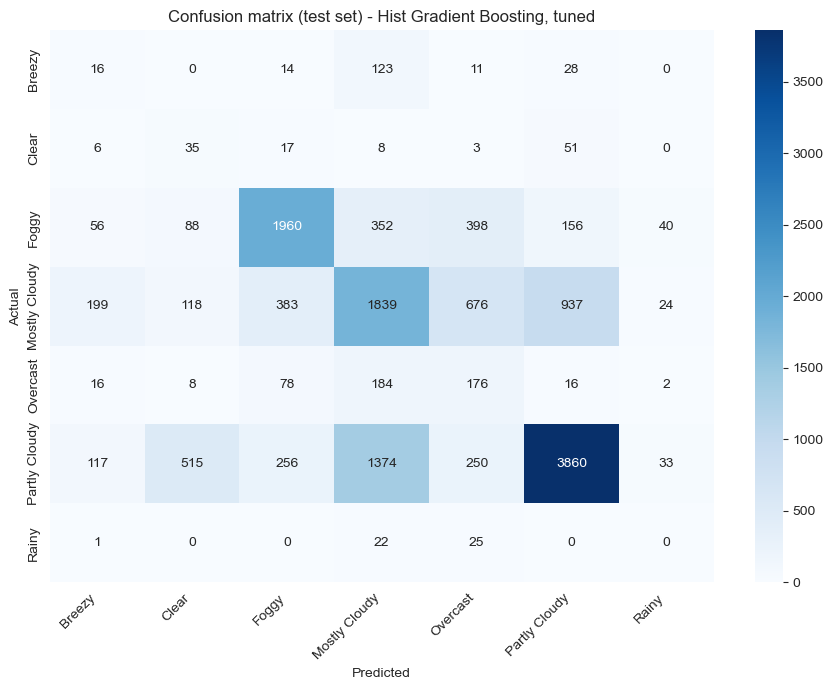

In [40]:
print(classification_report(y_test, preds['test'], labels=labels, target_names=label_encoder.classes_, zero_division=0))

cm = confusion_matrix(y_test, preds['test'], labels=labels)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion matrix (test set) - Hist Gradient Boosting, tuned')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

- Foggy (F1 0.68) and Partly Cloudy (0.67) are predicted best, Mostly Cloudy (0.46) is often confused with Partly Cloudy (1,374 and 937 rows).
- Overcast (0.17), Clear (0.08) and Breezy (0.05) have much higher recall than precision, so the model guesses them too often. For Overcast, 176 of the about 1,540 predictions are right.
- Rainy (2 days, 48 rows) is never predicted correctly: 22 rows go to Mostly Cloudy and 25 to Overcast. Rare-class scores rest on very few days (about 8 Breezy, 5 Clear and 2 Rainy days) and can change a lot with a different split.

#### AUC for each class

Breezy           0.758
Clear            0.835
Foggy            0.893
Mostly Cloudy    0.713
Overcast         0.780
Partly Cloudy    0.846
Rainy            0.483

Macro AUC: 0.758


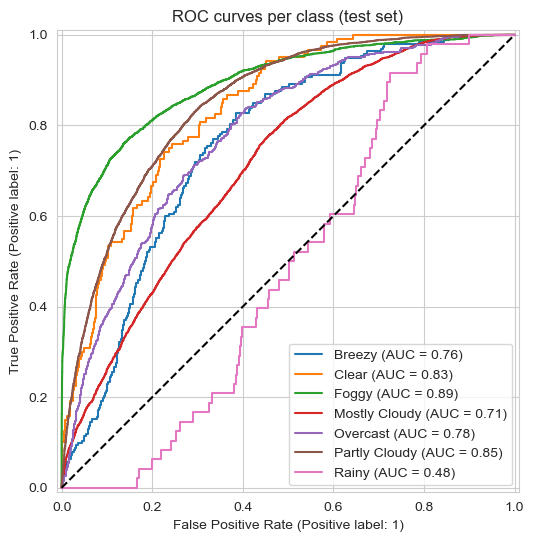

In [41]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay
from sklearn.preprocessing import label_binarize

proba = final_model.predict_proba(X_test_final)

# One-vs-rest AUC: for each class, how well does its predicted probability rank the days of that class
# above all other days? 0.5 = random guessing, 1.0 = perfect.
auc_per_class = roc_auc_score(y_test, proba, multi_class='ovr', average=None, labels=labels)
print(pd.Series(auc_per_class, index=label_encoder.classes_).round(3).to_string())
print(f"\nMacro AUC: {auc_per_class.mean():.3f}")

# ROC curves, one line per class
y_test_bin = label_binarize(y_test, classes=labels)
fig, ax = plt.subplots(figsize=(7, 6))
for i, name in enumerate(label_encoder.classes_):
    RocCurveDisplay.from_predictions(y_test_bin[:, i], proba[:, i], name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='random guessing')
ax.set_title('ROC curves per class (test set)')
plt.show()

AUC measures how well the predicted probability ranks days of a class above other days (0.5 is random guessing, 1.0 is perfect).
- Foggy (0.89), Partly Cloudy (0.85), Clear (0.84), Overcast (0.78) and Breezy (0.76) are all well above random, and Mostly Cloudy is 0.71. For Clear and Breezy this means the model's probabilities carry a real signal, even though the final labels have a low F1.
- Rainy has an AUC of 0.48, which is random. With 7 training days and 2 test days, the model cannot learn this class.
- The macro AUC is 0.758 (about 0.80 without Rainy).

## 19. Project summary

**Goal:** predict the daily weather summary (7 categories grouped from 214 original labels) from hourly weather readings. Data: about 96,400 hourly rows over 4,018 days (2006-2016).

**What I did**
- Grouped the 214 summaries into 7 categories with keyword rules, and checked the groups against the weather measurements.
- Found that each day has one label shared by all its hours, so I split by date (70/15/15) to avoid leakage between train and test.
- Fitted all preprocessing (missing values, outlier capping, encoding, scaling) on the train set only. Treated invalid zero readings of pressure and humidity as missing.
- Tested the features: date features helped on random days but not on later years, so I removed them and kept 9 weather features and month.
- Compared 11 models (including Hist Gradient Boosting, XGBoost and LightGBM) with 5-fold StratifiedGroupKFold, scored by macro F1, with class weights for the rare classes.
- Tuned the best model (Hist Gradient Boosting). The gain was small (CV macro F1 0.317 to 0.324), within the noise.

**Final result on the test set (used once)**

| | Accuracy | Macro F1 | Weighted F1 |
|---|---|---|---|
| Tuned Hist Gradient Boosting | 0.545 | 0.302 | 0.580 |
| Baseline (always Partly Cloudy) | 0.443 | 0.088 | 0.272 |

Foggy (F1 0.68) and Partly Cloudy (0.67) are predicted well, Mostly Cloudy is moderate (0.46), and Overcast, Clear, Breezy and Rainy are weak. Per-class AUC is 0.71 to 0.89 for six classes and 0.48 for Rainy.

**Limits**
- The label describes the whole day's sky, but each row is one hour of readings with no cloud-cover feature.
- Rainy, Breezy and Clear have very few days (Rainy: 7 in train, 2 in test), so their scores are unreliable.

**Possible next steps:** aggregate the hourly rows into one row per day (daily min, max and temperature range), and add cloud-cover data.

## 20. Deployment and monitoring

- The model needs only 9 inputs: temperature, apparent temperature, humidity, wind speed, wind bearing, visibility, pressure, month and precipitation type. No date features are used, so the app needs no year or day.
- The model, scaler, feature order and capping bounds are saved together in one file, so the app applies the same preprocessing as training.
- The label describes a whole day, but the model sees one hour of readings, so predictions for single hours are uncertain. The app should show the predicted probabilities, not only one label.
- Monitoring in production: track the input readings against the training ranges (drift), the share of each predicted category over time, and accuracy against real daily labels when they become available. Retrain when these move.
- Rainy, Breezy and Clear are too rare in the data to predict reliably, so their predictions should be treated with caution.

In [42]:
import pickle

# Scaler for the 9 final features only, so the app does not have to build the 19 training features.
# Every column is scaled on its own, so this gives the same values as the scaler used in training.
scaler_final = StandardScaler().fit(X_train[final_features])
assert np.allclose(scaler_final.transform(X_train[final_features]), X_train_final.values)

bundle = {
    'model': final_model,
    'scaler': scaler_final,
    'features': final_features,           # order the model expects
    'cap_bounds': bounds,                 # IQR bounds from the train set, for the 7 weather columns
    'classes': list(label_encoder.classes_),
}
with open('weather_model.pkl', 'wb') as f:
    pickle.dump(bundle, f)
print("Saved weather_model.pkl with", len(final_features), "features:", final_features)

Saved weather_model.pkl with 9 features: ['Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)', 'Month', 'Precip Type_snow']


In [43]:
from importlib.metadata import version, PackageNotFoundError

with open('requirements.txt', 'w') as f:
    for pkg in ['streamlit', 'scikit-learn', 'pandas', 'numpy']:
        try:
            f.write(f"{pkg}=={version(pkg)}\n")
        except PackageNotFoundError:
            f.write(f"{pkg}\n")   # not installed in this environment, pin it by hand
print(open('requirements.txt').read())

streamlit
scikit-learn==1.7.1
pandas==2.3.3
numpy==2.2.5



In [44]:
import os

os.makedirs(".streamlit", exist_ok=True)
with open(".streamlit/config.toml", "w") as f:
    f.write('''[theme]
base = "light"
primaryColor = "#FF5A1F"
backgroundColor = "#F3F6F8"
secondaryBackgroundColor = "#E6EDF3"
textColor = "#0F2233"
font = "sans serif"
''')

print("Working folder:", os.getcwd())
print("Inside .streamlit:", os.listdir(".streamlit"))

Working folder: C:\Users\Sai Kalyan\Downloads\Weather Summary Classification project by kalyan
Inside .streamlit: ['config.toml']
